[!] Không tìm thấy ../data/processed/telemetry_history.csv. Đang tạo dữ liệu mẫu để Demo EDA...
✅ Đã lưu biểu đồ sắc nét tại: ../wifi_rl_logs/collision_heatmap.png


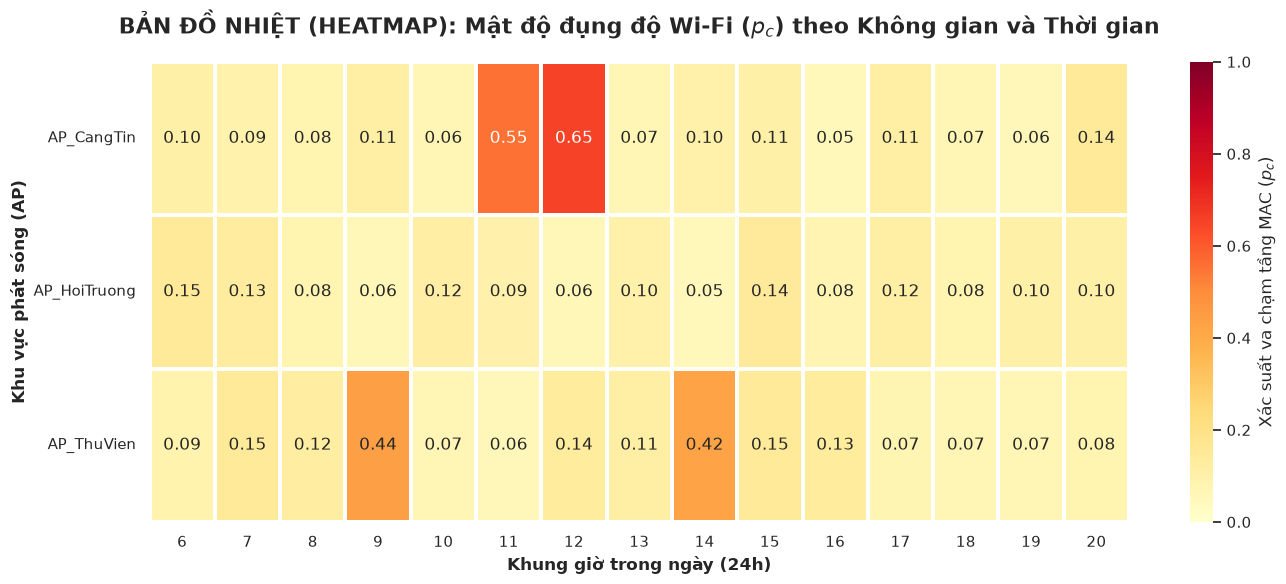

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. THIẾT LẬP ĐƯỜNG DẪN DỮ LIỆU CHUẨN
# ==========================================
# Lưu ý: Do file notebook nằm trong thư mục 'notebooks/', 
# ta phải lùi lại 1 thư mục gốc ('../') để vào 'data/processed/'
DATA_PATH = "../data/processed/telemetry_history.csv"

# ==========================================
# 2. HÀM ĐỌC HOẶC TẠO DỮ LIỆU MẪU (Mock Data)
# ==========================================
def load_or_mock_telemetry_data():
    if os.path.exists(DATA_PATH):
        print(f"[*] Đang tải dữ liệu thực tế từ: {DATA_PATH}")
        df = pd.read_csv(DATA_PATH)
    else:
        print(f"[!] Không tìm thấy {DATA_PATH}. Đang tạo dữ liệu mẫu để Demo EDA...")
        # Tạo dữ liệu giả lập cho 3 cục AP trong 14 tiếng (từ 6h sáng đến 20h tối)
        np.random.seed(42)
        hours = np.arange(6, 21)
        aps = ["AP_ThuVien", "AP_CangTin", "AP_HoiTruong"]
        
        data = []
        for ap in aps:
            for h in hours:
                # Giả lập: Căng tin nghẽn nặng lúc 11h-12h, Thư viện nghẽn lúc 9h và 14h
                base_pc = np.random.uniform(0.05, 0.15)
                if ap == "AP_CangTin" and h in [11, 12]: base_pc += np.random.uniform(0.4, 0.6)
                if ap == "AP_ThuVien" and h in [9, 14]: base_pc += np.random.uniform(0.3, 0.5)
                
                data.append({"Hour": h, "AP_Name": ap, "p_c": min(1.0, base_pc)})
        
        df = pd.DataFrame(data)
    return df

df = load_or_mock_telemetry_data()

# ==========================================
# 3. TIỀN XỬ LÝ DỮ LIỆU (Pivot Table)
# ==========================================
# Chuyển đổi DataFrame thành dạng Ma trận (Matrix) để vẽ Heatmap
# Trục tung (Index): Tên các AP
# Trục hoành (Columns): Các khung giờ trong ngày
# Giá trị (Values): Xác suất va chạm p_c
heatmap_data = df.pivot_table(index="AP_Name", columns="Hour", values="p_c", aggfunc=np.mean)

# ==========================================
# 4. TRỰC QUAN HÓA MULTIVARIATE: BẢN ĐỒ NHIỆT (HEATMAP)
# ==========================================
# Cấu hình phong cách biểu đồ chuẩn Báo cáo Khoa học
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 6))

# Vẽ Heatmap siêu đẹp
# cmap="YlOrRd" tạo hiệu ứng chuyển từ Vàng (An toàn) -> Cam -> Đỏ đậm (Nghẽn nặng)
ax = sns.heatmap(
    heatmap_data, 
    cmap="YlOrRd", 
    annot=True,          # Hiển thị con số trên từng ô
    fmt=".2f",           # Lấy 2 chữ số thập phân
    linewidths=1.5,      # Thêm viền trắng giữa các ô cho sang trọng
    cbar_kws={'label': 'Xác suất va chạm tầng MAC ($p_c$)'}, # Ghi chú cột màu
    vmin=0.0, vmax=1.0   # Giới hạn thang đo từ 0% đến 100%
)

# Tinh chỉnh tiêu đề và nhãn
plt.title("BẢN ĐỒ NHIỆT (HEATMAP): Mật độ đụng độ Wi-Fi ($p_c$) theo Không gian và Thời gian", 
          fontsize=16, fontweight='bold', pad=20)
plt.xlabel("Khung giờ trong ngày (24h)", fontsize=12, fontweight='bold')
plt.ylabel("Khu vực phát sóng (AP)", fontsize=12, fontweight='bold')

# Xoay nhãn trục Y để dễ đọc
plt.yticks(rotation=0, fontsize=11)
plt.xticks(fontsize=11)

# Lưu ảnh chất lượng cao 300 DPI để dán vào Word/LaTeX báo cáo
plt.tight_layout()
os.makedirs("../wifi_rl_logs", exist_ok=True)
output_img = "../wifi_rl_logs/collision_heatmap.png"
plt.savefig(output_img, dpi=300)
print(f"✅ Đã lưu biểu đồ sắc nét tại: {output_img}")

# Hiển thị ngay trên Notebook
plt.show()